# 03 — Merge & clean per-video transcript CSVs

Merges the per-video CSVs produced by `02_dataset_pipeline.ipynb` into a single
dataset file, drops failed rows (`Transcript == 'ERROR'`), and sanity-checks the
gender / mood distribution.

`combined.csv` in `../data/` is the final corpus metadata produced after all
batches were merged and cleaned (~29.9k utterances).

In [50]:
import pandas as pd
import os
import matplotlib.pyplot as plt

In [51]:
input_directory = "../data/batches"  # per-video CSVs from notebook 02  # Change this if your files are in a different directory
output_file = '../data/merged_output.csv'

In [52]:
csv_files = [file for file in os.listdir(input_directory) if file.endswith('.csv')]

In [53]:
merged_df = pd.DataFrame()

In [54]:
for i, file in enumerate(csv_files):
    file_path = os.path.join(input_directory, file)
    
    # Read the CSV file
    df = pd.read_csv(file_path)
    
    # Append to the merged dataframe
    if i == 0:
        # If it's the first file, include the header
        merged_df = df
    else:
        # If it's not the first file, exclude the header (column names)
        merged_df = pd.concat([merged_df, df], ignore_index=True)

In [55]:
# Save the merged DataFrame to a CSV file
merged_df.to_csv(output_file, index=False)

print(f"All files have been merged into {output_file}")

All files have been merged into merged_output.csv


In [56]:
# Path to the merged CSV file
merged_file_path = "../data/merged_output.csv"

# Load the merged CSV into a DataFrame
merged_df = pd.read_csv(merged_file_path)

# Get the number of rows before filtering
initial_rows = merged_df.shape[0]

# Remove rows where the 'transcript' column is 'ERROR'
merged_df = merged_df[merged_df['Transcript'] != 'ERROR']

# Get the number of rows after filtering
final_rows = merged_df.shape[0]

# Calculate how many rows were removed
rows_removed = initial_rows - final_rows

# Overwrite the original file with the cleaned DataFrame
merged_df.to_csv(merged_file_path, index=False)

# Print the number of rows removed and remaining
print(f"Rows removed: {rows_removed}")
print(f"Rows remaining: {final_rows}")

Rows removed: 0
Rows remaining: 11109


In [57]:
merged_df.sample(20)

,Audio Path,Transcript,Gender,Age,Mood,Accent
646,wave_transcript/حصرياً فيلم حملة فريزر ｜ بطولة...,ليه ليه ده انا بعت اهلي والنادي الاهلي عشان بح...,male,adult,neutral,Egyptian Arabic
3545,wave_transcript/Al Frenga - Season 01 - Episod...,عناصر من الجيزه,female,adult,calm,Egyptian Arabic
8578,wave_transcript/صاحبة السعادة ｜ ＂ الدنيا برد ...,انجمن بندق لوز 17,female,adult,calm,Egyptian Arabic
10264,wave_transcript/شيماء سيف تكشف تفاصيل خسارة وز...,هل ده لانك انت كنت عايشه مع ماما وبابا وبابا و...,female,adult,calm,Egyptian Arabic
8393,wave_transcript/حصرياً فيلم حملة فريزر ｜ بطولة...,مفتول العضلات ممشوق القامه اللي هيلعب قدامي دو...,male,adult,calm,Egyptian Arabic
10761,wave_transcript/Al Frenga - Season 03 - Episod...,لا بحبهم,female,adult,calm,Egyptian Arabic
6939,wave_transcript/Al Frenga - Season 02 - Episod...,صاحبي اللي سافر جواب هقول له ان صاحبك حبيبك تعب,male,adult,calm,Egyptian Arabic
723,wave_transcript/فيلم البعض لا يذهب للماذون مرت...,‏good morning,male,adult,calm,Egyptian Arabic
793,wave_transcript/حصرياً فيلم حملة فريزر ｜ بطولة...,الله يخرب بيتك يا مديح الكلب,male,adult,calm,Egyptian Arabic
7498,wave_transcript/حصرياً فيلم حملة فريزر ｜ بطولة...,الحمد لله الحمد لله بعد ما انقذها اغتصبها برضو...,male,adult,calm,Egyptian Arabic


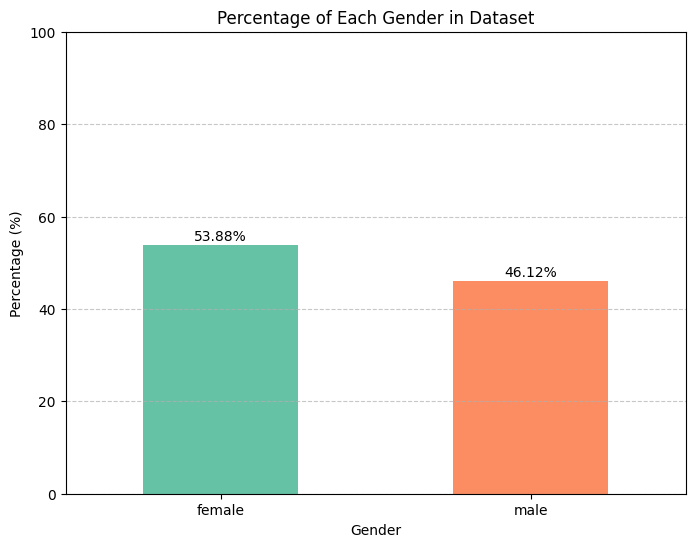

In [58]:
# Load the cleaned merged CSV file
merged_df = pd.read_csv(merged_file_path)

# Normalize the 'gender' column to lowercase and remove leading/trailing spaces
merged_df['Gender'] = merged_df['Gender'].str.lower().str.strip()

# Count the number of occurrences of each gender
gender_counts = merged_df['Gender'].value_counts()

# Calculate the percentage of each gender
gender_percentages = (gender_counts / gender_counts.sum()) * 100

# Plot the percentages as a bar chart
plt.figure(figsize=(8, 6))
gender_percentages.plot(kind='bar', color=['#66c2a5', '#fc8d62', '#8da0cb'])

# Customize plot
plt.title('Percentage of Each Gender in Dataset')
plt.xlabel('Gender')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show percentage on top of each bar
for index, value in enumerate(gender_percentages):
    plt.text(index, value + 1, f'{value:.2f}%', ha='center')

# Show the plot
plt.show()

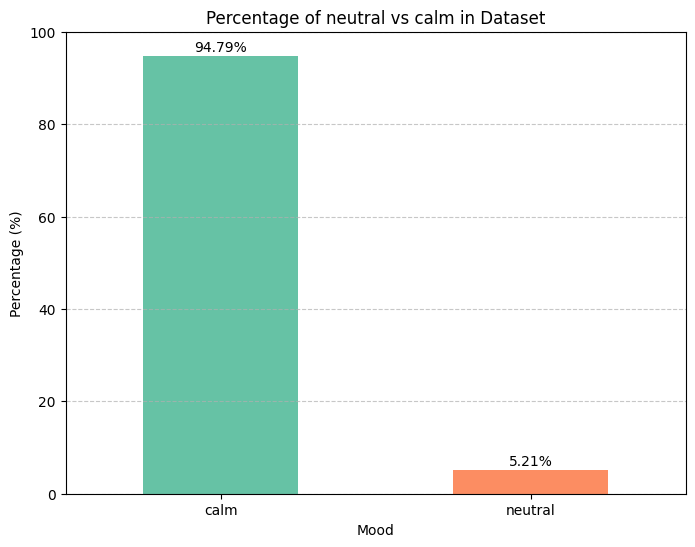

In [59]:
# Load the cleaned merged CSV file
merged_df = pd.read_csv(merged_file_path)

# Normalize the 'noisy_level' column to lowercase and remove leading/trailing spaces
merged_df['Mood'] = merged_df['Mood'].str.lower().str.strip()

# Count the number of occurrences of each Mood
noisy_counts = merged_df['Mood'].value_counts()

# Calculate the percentage of each Mood
noisy_percentages = (noisy_counts / noisy_counts.sum()) * 100

# Plot the percentages as a bar chart
plt.figure(figsize=(8, 6))
noisy_percentages.plot(kind='bar', color=['#66c2a5', '#fc8d62'])

# Customize plot
plt.title('Percentage of neutral vs calm in Dataset')
plt.xlabel('Mood')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show percentage on top of each bar
for index, value in enumerate(noisy_percentages):
    plt.text(index, value + 1, f'{value:.2f}%', ha='center')

# Show the plot
plt.show()